<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/09-math-in-code/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 9: Math in Code

Machine learning is built on a small amount of maths: vectors and matrices, derivatives, probability and statistics. You don't need to prove theorems to use it, but you do need to be able to read a formula, turn it into code, and check that the code is right.

That last part is what this module is about. Every idea here follows the same three steps:

1. **Write the formula** in plain notation.
2. **Implement it** in NumPy, usually in a few lines.
3. **Check it** against something independent: a simulation, a numerical approximation, or a library function.

The third step is the habit that matters most. A wrong gradient or a wrong probability doesn't crash. It just gives you a model that's quietly worse, and you won't know why.

**Contents**

1. Numbers on a computer
2. Vectors and matrices
3. Derivatives, numerically
4. Gradients
5. The chain rule, and a tiny autodiff engine
6. Gradient descent
7. Probability by simulation
8. Statistics: estimates and their uncertainty
9. Information: entropy and cross-entropy

## Setup

NumPy for the maths, pandas to load the penguins, and the course plotting style from Module 8.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL)
print(penguins.shape)

(344, 8)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. Numbers on a computer

Before any maths, it helps to know how the computer stores numbers, because it's the source of some very confusing bugs.

Python's `float` (and NumPy's `float64`) is a **binary floating-point** number. It stores about 16 significant decimal digits, and most decimal fractions can't be represented exactly:

In [3]:
print(0.1 + 0.2)
print(0.1 + 0.2 == 0.3)
print(np.isclose(0.1 + 0.2, 0.3))
print("machine epsilon:", np.finfo(float).eps)

0.30000000000000004
False
True
machine epsilon: 2.220446049250313e-16


`0.1` in binary is a repeating fraction, like 1/3 in decimal, so it gets rounded. The rounding errors are tiny, about 1 part in 10<sup>16</sup> (machine epsilon), but they mean **you should never compare floats with `==`**. Use `np.isclose` or `math.isclose`, which allow a small tolerance.

Tiny errors are usually harmless. They become a problem in two situations.

### Subtracting nearly equal numbers

Here's a formula for the variance from any statistics textbook: the mean of the squares minus the square of the mean. It's mathematically correct. Watch what happens with large values:

In [4]:
x = np.array([1e9 + 4, 1e9 + 7, 1e9 + 13, 1e9 + 16])

textbook = np.mean(x ** 2) - np.mean(x) ** 2
two_pass = np.mean((x - x.mean()) ** 2)
print("mean of squares minus square of mean:", textbook)
print("mean of squared deviations:          ", two_pass)
print("np.var:                              ", np.var(x))

mean of squares minus square of mean: -128.0
mean of squared deviations:           22.5
np.var:                               22.5


A **negative variance**, which is impossible. Both `x ** 2` and `mean(x) ** 2` are around 10<sup>18</sup>, and they agree in their first 16 digits. Subtracting them leaves only the rounding noise. This is called **catastrophic cancellation**.

The fix is to rearrange the formula so you never subtract two huge, nearly equal numbers: subtract the mean first, then square. That's what `np.var` does. Timestamps, coordinates and IDs are all large numbers where this can happen.

### Overflow, and the softmax

`np.exp` overflows above about 709, because the result is bigger than the largest float. The softmax from Module 6 exponentiates its inputs, and large scores are common in neural networks:

In [5]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()


z = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    print("naive:", softmax_naive(z))

naive: [nan nan nan]


`exp(1000)` is infinity, and infinity divided by infinity is `nan`. The fix uses a property of softmax: adding or subtracting the same number from every score doesn't change the result, because the factor cancels between the top and bottom:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}} = \frac{e^{z_i - c}}{\sum_j e^{z_j - c}}$$

Choose `c = max(z)`, so the largest exponent is `e^0 = 1` and nothing can overflow:

In [6]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()


print("stable:", softmax(z))
print("same as small scores:", softmax(np.array([0.0, 1.0, 2.0])))

stable: [0.09003057 0.24472847 0.66524096]
same as small scores: [0.09003057 0.24472847 0.66524096]


The same trick gives the **log-sum-exp**, `log(sum(exp(z)))`, which appears in every cross-entropy loss:

$$\log \sum_j e^{z_j} = c + \log \sum_j e^{z_j - c}$$

You'll write both as exercises. Every deep learning library uses these stable versions internally, which is why you should use their built-in loss functions instead of writing `log(softmax(z))` yourself.

## 2. Vectors and matrices

In ML code, a **vector** is a 1D array: one penguin's measurements, one word's embedding, a model's weights. A **matrix** is a 2D array: a dataset (one row per example), or a set of weights mapping one vector to another.

### The dot product

The dot product multiplies matching elements and adds them up:

$$a \cdot b = \sum_i a_i b_i$$

It's the most used operation in ML. A linear model's prediction is a dot product of weights and features. Every layer in a neural network is a batch of dot products.

In [7]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, -5.0, 6.0])

print("by hand: ", sum(ai * bi for ai, bi in zip(a, b)))
print("np.dot:  ", np.dot(a, b))
print("a @ b:   ", a @ b)

by hand:  12.0
np.dot:   12.0
a @ b:    12.0


### Length, and cosine similarity

The **norm** (length) of a vector is `sqrt(a · a)`, Pythagoras in any number of dimensions. Dividing a dot product by both lengths gives the **cosine similarity**, the cosine of the angle between the vectors:

$$\cos\theta = \frac{a \cdot b}{\|a\|\,\|b\|}$$

It's 1 when the vectors point the same way, 0 when they're perpendicular, and -1 when they're opposite, regardless of length. That's why it's used to compare text embeddings: a long document and a short one about the same topic point the same way, even though one vector is longer.

In [8]:
def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))


# made-up "taste" vectors: [action, comedy, romance, documentary]
ana = np.array([5.0, 1.0, 0.0, 2.0])
ben = np.array([4.0, 2.0, 0.0, 1.0])
cara = np.array([0.0, 1.0, 5.0, 0.0])
dev = 3 * ana                      # same tastes as Ana, just rates everything higher

print(f"Ana and Ben:  {cosine_similarity(ana, ben):.3f}")
print(f"Ana and Cara: {cosine_similarity(ana, cara):.3f}")
print(f"Ana and Dev:  {cosine_similarity(ana, dev):.3f}")
print(f"norms: Ana {np.linalg.norm(ana):.2f}, Dev {np.linalg.norm(dev):.2f}")

Ana and Ben:  0.956
Ana and Cara: 0.036
Ana and Dev:  1.000
norms: Ana 5.48, Dev 16.43


Dev's vector is three times longer than Ana's, but the similarity is exactly 1: same direction, same tastes.

### Matrix times vector

Multiplying a matrix by a vector takes the dot product of each **row** with the vector. With a dataset `X` (one row per example) and weights `w`, `X @ w` computes a prediction for every example in one line. That's what made Module 6's linear regression fast.

The shape rule: `(n, d) @ (d,)` gives `(n,)`, and `(n, d) @ (d, k)` gives `(n, k)`. The inner sizes must match. When a matrix multiplication fails, writing down the shapes almost always shows why.

In [9]:
X = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])            # 3 examples, 2 features
w = np.array([0.5, -1.0])

print("X @ w:", X @ w)
print("row by row:", [float(row @ w) for row in X])
print("shapes:", X.shape, "@", w.shape, "->", (X @ w).shape)

X @ w: [-1.5 -2.5 -3.5]
row by row: [-1.5, -2.5, -3.5]
shapes: (3, 2) @ (2,) -> (3,)


A matrix can also be seen as a **transformation** of space: it moves every point somewhere else. Here a 2x2 matrix acts on points around a circle:

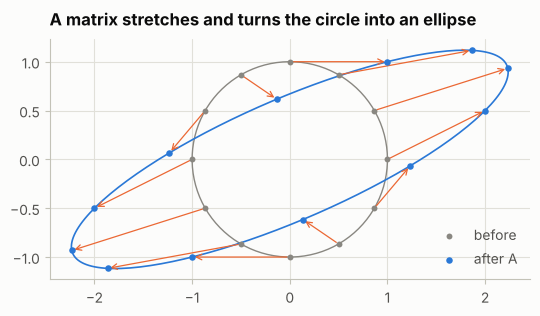

In [10]:
A = np.array([[2.0, 1.0],
              [0.5, 1.0]])
angles = np.linspace(0, 2 * np.pi, 13)[:-1]
circle = np.column_stack([np.cos(angles), np.sin(angles)])   # 12 points, shape (12, 2)
moved = circle @ A.T                                            # A applied to every point

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ring = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(ring), np.sin(ring), color=MUTED, linewidth=1)
ax.plot(*(np.column_stack([np.cos(ring), np.sin(ring)]) @ A.T).T, color=PALETTE[0], linewidth=1.2)
for p, q in zip(circle, moved):
    ax.annotate("", xy=q, xytext=p, arrowprops={"arrowstyle": "->", "color": PALETTE[1], "lw": 0.9})
ax.scatter(*circle.T, color=MUTED, s=18, zorder=3, label="before")
ax.scatter(*moved.T, color=PALETTE[0], s=22, zorder=3, label="after A")
ax.set_aspect("equal")
ax.set_title("A matrix stretches and turns the circle into an ellipse")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

`circle @ A.T` applies `A` to every row at once. (Each row is a point, so we multiply by the transpose; for a single column vector you'd write `A @ p`.) Each layer of a neural network is a transformation like this, followed by a non-linearity.

### Solving linear systems

Many methods end in a system of equations `A x = b`. It's tempting to compute the inverse and write `x = inv(A) @ b`, but `np.linalg.solve` is faster and more accurate, and for least squares (more equations than unknowns) `np.linalg.lstsq` is the right tool:

In [11]:
A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

x = np.linalg.solve(A, b)
print("solution:", x)
print("check A @ x == b:", np.allclose(A @ x, b))

solution: [2. 3.]
check A @ x == b: True


Notice the check at the end. Plugging the answer back in is the simplest independent test there is.

## 3. Derivatives, numerically

The **derivative** of a function at a point is its slope there: how much the output changes per unit change in the input. Training a model is about following slopes downhill, so derivatives are everywhere in ML.

The definition is a limit:

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

A computer can't take a limit, but it can use a small `h`. This is a **finite difference**. There's a better version, the **central difference**, which looks a step either side:

$$f'(x) \approx \frac{f(x + h) - f(x - h)}{2h}$$

Let's test both on `sin`, whose derivative we know is `cos`:

In [12]:
def forward_diff(f, x, h):
    return (f(x + h) - f(x)) / h


def central_diff(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)


x0 = 1.0
exact = np.cos(x0)
for h in [1e-1, 1e-3, 1e-5]:
    print(f"h={h:<6g} forward error {abs(forward_diff(np.sin, x0, h) - exact):.1e}   "
          f"central error {abs(central_diff(np.sin, x0, h) - exact):.1e}")

h=0.1    forward error 4.3e-02   central error 9.0e-04
h=0.001  forward error 4.2e-04   central error 9.0e-08
h=1e-05  forward error 4.2e-06   central error 1.1e-11


Each time `h` shrinks 100 times, the forward error shrinks 100 times, but the central error shrinks 10,000 times. The forward difference's error is proportional to `h`; the central one's is proportional to `h²`, because the errors on each side cancel.

So should `h` be as small as possible? No. Section 1 strikes again: with a tiny `h`, `f(x + h)` and `f(x - h)` are nearly equal and their difference is mostly rounding noise. Here's the full picture:

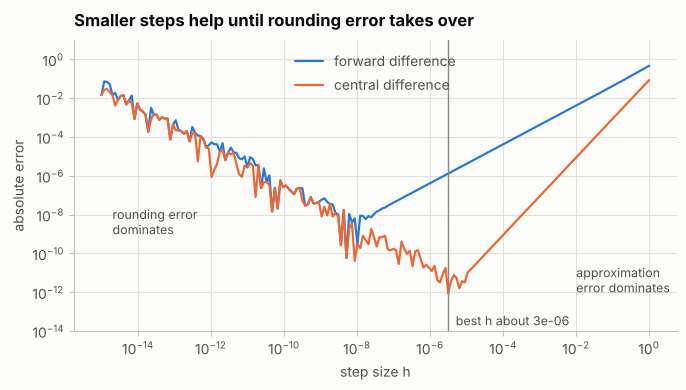

In [13]:
hs = np.logspace(-15, 0, 200)
forward_err = np.abs([forward_diff(np.sin, x0, h) - exact for h in hs])
central_err = np.abs([central_diff(np.sin, x0, h) - exact for h in hs])

fig, ax = plt.subplots()
ax.loglog(hs, forward_err, color=PALETTE[0], label="forward difference")
ax.loglog(hs, central_err, color=PALETTE[1], label="central difference")
best = hs[np.argmin(central_err)]
ax.axvline(best, color=MUTED, linewidth=1)
ax.set_ylim(1e-14, 10)
ax.text(best * 1.6, 2e-14, f"best h about {best:.0e}", color=INK_2, fontsize=9)
ax.text(2e-15, 1e-9, "rounding error\ndominates", color=INK_2, fontsize=9)
ax.text(1e-2, 1e-12, "approximation\nerror dominates", color=INK_2, fontsize=9)
ax.set_xlabel("step size h")
ax.set_ylabel("absolute error")
ax.set_title("Smaller steps help until rounding error takes over")
ax.legend(loc="upper center")
fig.tight_layout()
plt.show()

A V shape. To the right, the approximation is too coarse; to the left, rounding noise is divided by a tiny `h` and blows up. The central difference bottoms out around 10<sup>-11</sup> to 10<sup>-12</sup>, for `h` between roughly 10<sup>-6</sup> and 10<sup>-5</sup>, which is why `h = 1e-5` is a common default. The forward difference can't do better than about 10<sup>-8</sup>.

Numerical derivatives are too slow to train models with (one function call per parameter), but they're the standard way to **check** a derivative you worked out by hand. You'll do exactly that in the mini project.

## 4. Gradients

A model has many parameters, so its loss is a function of many inputs. The **partial derivative** with respect to one input is the slope when you change only that input. The **gradient** collects all of them into a vector:

$$\nabla f(x) = \left( \frac{\partial f}{\partial x_1}, \ldots, \frac{\partial f}{\partial x_d} \right)$$

The numerical version nudges one coordinate at a time:

In [14]:
def numerical_gradient(f, x, h=1e-5):
    x = np.asarray(x, dtype=float)
    grad = np.zeros_like(x)
    for i in range(x.size):
        step = np.zeros_like(x)
        step[i] = h
        grad[i] = (f(x + step) - f(x - step)) / (2 * h)
    return grad


def bowl(p):
    x, y = p
    return x ** 2 + 3 * y ** 2


def bowl_grad(p):                 # worked out by hand: d/dx = 2x, d/dy = 6y
    x, y = p
    return np.array([2 * x, 6 * y])


point = np.array([1.0, -2.0])
print("by hand:  ", bowl_grad(point))
print("numerical:", numerical_gradient(bowl, point))

by hand:   [  2. -12.]
numerical: [  2. -12.]


They agree. That's a **gradient check**, and it's the fastest way to catch a mistake in a derivative.

The gradient has a geometric meaning: it points in the direction where the function **increases fastest**, and it's perpendicular to the contour lines. To go downhill, step the other way.

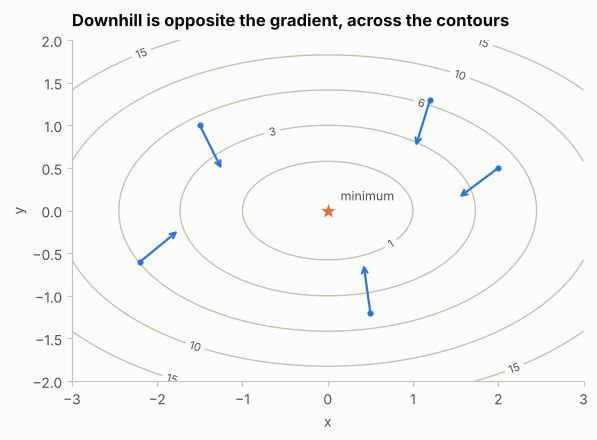

In [15]:
gx, gy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-2, 2, 200))
gz = gx ** 2 + 3 * gy ** 2

fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contour(gx, gy, gz, levels=[1, 3, 6, 10, 15], colors=AXIS, linewidths=1)
ax.clabel(cs, fontsize=8, colors=INK_2)
pts = np.array([[2.0, 0.5], [-1.5, 1.0], [0.5, -1.2], [-2.2, -0.6], [1.2, 1.3]])
for p in pts:
    g = bowl_grad(p)
    d = -g / np.linalg.norm(g) * 0.6          # unit downhill direction, scaled to fit
    ax.annotate("", xy=p + d, xytext=p, arrowprops={"arrowstyle": "->", "color": PALETTE[0], "lw": 1.6})
ax.scatter(*pts.T, color=PALETTE[0], s=20, zorder=3)
ax.scatter([0], [0], color=PALETTE[1], marker="*", s=120, zorder=3)
ax.text(0.15, 0.12, "minimum", color=INK_2, fontsize=9)
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Downhill is opposite the gradient, across the contours")
fig.tight_layout()
plt.show()

The arrows (the negative gradient) cross every contour at a right angle. Notice they **don't point at the minimum**. Because the bowl is steeper in `y` than in `x`, the steepest direction leans towards the `y = 0` line first. That detail matters in section 6.

## 5. The chain rule, and a tiny autodiff engine

Models are compositions of simple functions: multiply, add, apply an activation, compute a loss. The **chain rule** says how to differentiate a composition: multiply the derivatives of the pieces.

$$\frac{d}{dx} f(g(x)) = f'(g(x)) \cdot g'(x)$$

Take a single neuron: `y = tanh(w * x + b)`. Break it into steps and differentiate each:

| step | value | local derivative |
|---|---|---|
| `u = w * x` | | `du/dw = x` |
| `v = u + b` | | `dv/du = 1`, `dv/db = 1` |
| `y = tanh(v)` | | `dy/dv = 1 - tanh(v)²` |

So `dy/dw = (1 - y²) · 1 · x`. Working backwards from the output, multiplying local derivatives, is **backpropagation**. That's all it is.

In [16]:
w, x, b = 0.7, 1.5, -0.4
y = np.tanh(w * x + b)
dy_dw = (1 - y ** 2) * x
dy_db = (1 - y ** 2)

h = 1e-6
print(f"dy/dw by chain rule {dy_dw:.6f}, numerical {(np.tanh((w + h) * x + b) - np.tanh((w - h) * x + b)) / (2 * h):.6f}")
print(f"dy/db by chain rule {dy_db:.6f}, numerical {(np.tanh(w * x + b + h) - np.tanh(w * x + b - h)) / (2 * h):.6f}")

dy/dw by chain rule 1.009790, numerical 1.009790
dy/db by chain rule 0.673193, numerical 0.673193


Libraries like PyTorch do this automatically: every operation records how to compute its local derivative, and `.backward()` walks the steps in reverse. You can build the core of that in about 40 lines, using the operator overloading from Module 3:

In [17]:
class Value:
    """A number that remembers how it was computed, so it can backpropagate."""

    def __init__(self, data, parents=(), op=""):
        self.data = float(data)
        self.grad = 0.0
        self._parents = parents
        self._backward = lambda: None
        self.op = op

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def backward():
            self.grad += out.grad           # d(a + b)/da = 1
            other.grad += out.grad          # d(a + b)/db = 1
        out._backward = backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def backward():
            self.grad += other.data * out.grad    # d(a * b)/da = b
            other.grad += self.data * out.grad    # d(a * b)/db = a
        out._backward = backward
        return out

    __radd__ = __add__
    __rmul__ = __mul__

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,), "tanh")

        def backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = backward
        return out

    def backward(self):
        # order the graph so each node comes after everything it depends on
        order, seen = [], set()

        def visit(node):
            if id(node) not in seen:
                seen.add(id(node))
                for parent in node._parents:
                    visit(parent)
                order.append(node)
        visit(self)
        self.grad = 1.0
        for node in reversed(order):
            node._backward()

    def __repr__(self):
        return f"Value({self.data:.4f}, grad={self.grad:.4f})"


w, x, b = Value(0.7), Value(1.5), Value(-0.4)
y = (w * x + b).tanh()
y.backward()
print("y =", y)
print("w:", w)
print("b:", b)

y = Value(0.5717, grad=1.0000)
w: Value(0.7000, grad=1.0098)
b: Value(-0.4000, grad=0.6732)


Same numbers as the hand calculation. Two details are worth noticing:

- **Gradients are added with `+=`, not set.** If a value is used twice, as in `x * x`, both uses contribute to its gradient. Setting instead of adding is a classic backprop bug.
- **The order matters.** A node's `_backward` can only run once its own gradient is complete, which is why `backward()` sorts the graph first.

A quick test of the first point:

In [18]:
a = Value(3.0)
c = a * a + a          # c = a² + a, so dc/da = 2a + 1 = 7
c.backward()
print("dc/da =", a.grad)

dc/da = 7.0


This is the same idea as PyTorch's autograd, just for single numbers instead of arrays.

## 6. Gradient descent

To minimise a loss, start somewhere and repeatedly take a small step downhill:

$$x \leftarrow x - \eta \, \nabla f(x)$$

`η` (eta) is the **learning rate**. Here it is on a bowl that's ten times steeper in one direction than the other, `f(x, y) = x² + 10y²`:

In [19]:
def stretched(p):
    return p[0] ** 2 + 10 * p[1] ** 2


def stretched_grad(p):
    return np.array([2 * p[0], 20 * p[1]])


def descend(grad, start, lr, steps):
    path = [np.array(start, dtype=float)]
    for _ in range(steps):
        path.append(path[-1] - lr * grad(path[-1]))
    return np.array(path)


start = [-4.0, 1.5]
runs = {0.02: "too small", 0.09: "about right", 0.101: "too big"}
paths = {lr: descend(stretched_grad, start, lr, 40) for lr in runs}
for lr, path in paths.items():
    print(f"lr={lr:<6} loss after 40 steps: {stretched(path[-1]):.3g}")

lr=0.02   loss after 40 steps: 0.611
lr=0.09   loss after 40 steps: 2.44e-06
lr=0.101  loss after 40 steps: 110


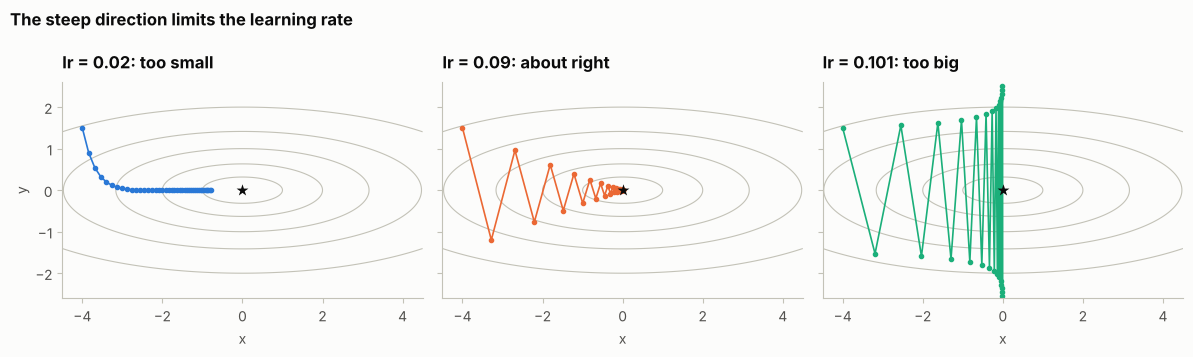

In [20]:
gx, gy = np.meshgrid(np.linspace(-4.5, 4.5, 300), np.linspace(-2.6, 2.6, 300))
gz = gx ** 2 + 10 * gy ** 2

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (lr, label), colour in zip(axes, runs.items(), PALETTE):
    path = paths[lr]
    ax.contour(gx, gy, gz, levels=[1, 4, 10, 20, 40], colors=AXIS, linewidths=0.8)
    shown = path[np.all(np.abs(path) < [4.5, 2.6], axis=1)]
    ax.plot(shown[:, 0], shown[:, 1], color=colour, marker="o", markersize=3, linewidth=1.2)
    ax.scatter([0], [0], color=INK, marker="*", s=80, zorder=3)
    ax.set_title(f"lr = {lr}: {label}")
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-2.6, 2.6)
    ax.grid(False)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
fig.suptitle("The steep direction limits the learning rate", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Three behaviours from one algorithm:

- **Too small** (0.02): every step is safe, but after 40 steps it's still far from the minimum along the shallow `x` direction.
- **About right** (0.09): it zigzags across the steep `y` direction while it makes progress along `x`.
- **Too big** (0.101): the `y` coordinate overshoots further each step and the loss explodes.

Why does it blow up at just over 0.1? Each step multiplies `y` by `1 - η · 20`. Once `η > 2 / 20 = 0.1`, that factor is bigger than 1 in size, so `y` grows. **The steepest direction sets the largest safe learning rate**, and the shallowest direction sets how many steps you need. The bigger the ratio between them, the harder the problem.

That's the maths behind a rule from Module 6: **standardise your features**. Features on very different scales make the loss surface a long, narrow valley like this one. Standardising makes it rounder, so one learning rate suits every direction.

### Check: gradient descent against the exact answer

For linear regression there's an exact solution (least squares), so we can check gradient descent against it. Predicting body mass from flipper length:

In [21]:
data = penguins.dropna(subset=["flipper_length_mm", "body_mass_g"])
x_raw = data["flipper_length_mm"].to_numpy()
y_kg = data["body_mass_g"].to_numpy() / 1000

# exact answer with least squares: columns [x, 1] for slope and intercept
exact_slope, exact_intercept = np.linalg.lstsq(np.column_stack([x_raw, np.ones_like(x_raw)]), y_kg, rcond=None)[0]

# gradient descent on the mean squared error, with a standardised feature
mu, sd = x_raw.mean(), x_raw.std()
xs = (x_raw - mu) / sd
w, b = 0.0, 0.0
for step in range(200):
    error = (w * xs + b) - y_kg
    w -= 0.1 * 2 * np.mean(error * xs)          # d(MSE)/dw
    b -= 0.1 * 2 * np.mean(error)               # d(MSE)/db

# convert back to the original units
gd_slope = w / sd
gd_intercept = b - w * mu / sd
print(f"least squares:    slope {exact_slope:.5f} kg/mm, intercept {exact_intercept:.4f} kg")
print(f"gradient descent: slope {gd_slope:.5f} kg/mm, intercept {gd_intercept:.4f} kg")

least squares:    slope 0.04969 kg/mm, intercept -5.7808 kg
gradient descent: slope 0.04969 kg/mm, intercept -5.7808 kg


Same line, found two different ways: about 50 g more body mass for every extra millimetre of flipper. When two independent methods agree, you can trust both. When gradient descent is the only option (logistic regression, neural networks), a case like this, where an exact answer exists, is how you test your training code.

## 7. Probability by simulation

Probability questions can be surprisingly hard to reason about, and easy to simulate. With a random number generator and a few million samples, you can check almost any probability calculation.

In [22]:
rng = np.random.default_rng(42)

### The law of large numbers

The average of many independent samples gets closer to the true mean as you take more samples. A fair die has mean 3.5:

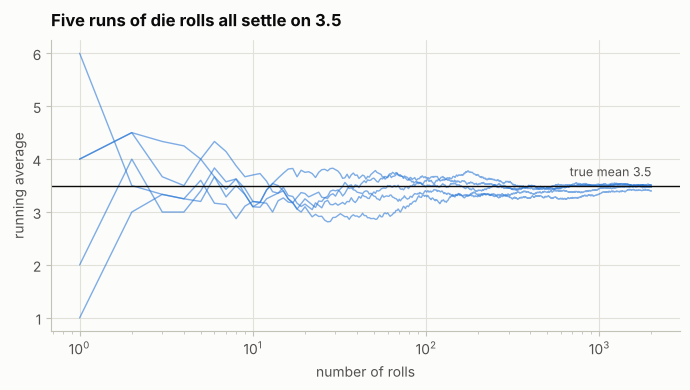

In [23]:
rolls = rng.integers(1, 7, size=(5, 2000))                     # 5 runs of 2000 rolls
running = rolls.cumsum(axis=1) / np.arange(1, 2001)

fig, ax = plt.subplots()
for run in running:
    ax.plot(np.arange(1, 2001), run, color=PALETTE[0], alpha=0.6, linewidth=1)
ax.axhline(3.5, color=INK, linewidth=1)
ax.text(2000, 3.62, "true mean 3.5", color=INK_2, ha="right", va="bottom", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("number of rolls")
ax.set_ylabel("running average")
ax.set_title("Five runs of die rolls all settle on 3.5")
fig.tight_layout()
plt.show()

After a handful of rolls the runs are all over the place; after a thousand they agree to within about 0.1. The error shrinks like `1 / sqrt(n)`, a fact that comes back in section 8: to halve the error, you need **four times** the data.

### Conditional probability and Bayes' rule

A classic. A disease affects 1% of people. A test for it catches 95% of real cases (its **sensitivity**) and correctly clears 90% of healthy people (its **specificity**). You test positive. What's the chance you have the disease?

Most people guess around 90%. Bayes' rule gives the answer:

$$P(\text{disease} \mid +) = \frac{P(+ \mid \text{disease}) \, P(\text{disease})}{P(+)}$$

where `P(+)` counts both ways of testing positive, sick and correctly flagged, or healthy and wrongly flagged:

In [24]:
prevalence, sensitivity, specificity = 0.01, 0.95, 0.90

p_positive = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
posterior = sensitivity * prevalence / p_positive
print(f"P(disease | positive) by Bayes' rule: {posterior:.3f}")

P(disease | positive) by Bayes' rule: 0.088


Under 9%. It feels wrong, so check it the other way, by simulating a million people:

In [25]:
n = 1_000_000
sick = rng.random(n) < prevalence
positive = np.where(sick, rng.random(n) < sensitivity, rng.random(n) > specificity)

print(f"people who tested positive: {positive.sum():,}")
print(f"of those, actually sick:    {sick[positive].sum():,}")
print(f"fraction sick:              {sick[positive].mean():.3f}")

people who tested positive: 108,391
of those, actually sick:    9,501
fraction sick:              0.088


The simulation agrees. The intuition: out of a million people, 10,000 are sick and 9,500 of them test positive. But 990,000 are healthy, and 10% of them, 99,000 people, also test positive. Positives from healthy people outnumber real cases ten to one.

This is the **base rate** problem, and it applies directly to ML. A fraud model with 95% recall and a 10% false positive rate sounds good, but if only 1% of transactions are fraud, most of its alerts will be false alarms. Always ask how rare the positive class is.

### Distributions

A **distribution** describes how likely each value is. NumPy's generator can sample from all the common ones. The **normal** (Gaussian) distribution has a formula you'll see constantly:

$$p(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)$$

Checking the formula against samples:

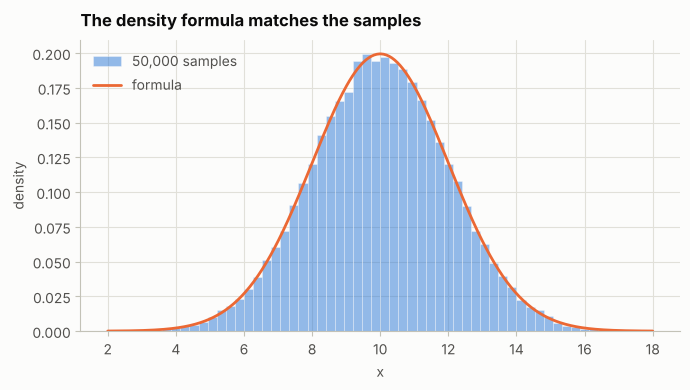

In [26]:
def normal_pdf(x, mu, sigma):
    return np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))


samples = rng.normal(loc=10, scale=2, size=50_000)
edges = np.linspace(2, 18, 61)
xs = np.linspace(2, 18, 400)

fig, ax = plt.subplots()
ax.hist(samples, bins=edges, density=True, color=PALETTE[0], alpha=0.5, edgecolor=SURFACE, linewidth=0.5,
        label="50,000 samples")
ax.plot(xs, normal_pdf(xs, 10, 2), color=PALETTE[1], linewidth=2, label="formula")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_title("The density formula matches the samples")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

`density=True` scales the histogram so its total area is 1, the same as the formula, which makes them comparable. About 68% of samples fall within one standard deviation of the mean, and about 95% within two:

In [27]:
for k in [1, 2, 3]:
    inside = np.mean(np.abs(samples - 10) < k * 2)
    print(f"within {k} sd: {inside:.3f}")

within 1 sd: 0.682
within 2 sd: 0.954
within 3 sd: 0.997


## 8. Statistics: estimates and their uncertainty

A statistic computed from data is an **estimate**. Collect different data and you'd get a different number. Knowing how much it could vary is as important as the number itself, especially when you compare two models.

### Why `ddof=1`?

The variance of a sample divides by `n`. But a sample's points are, on average, closer to their own mean than to the true mean, so dividing by `n` **underestimates** the true variance. Dividing by `n - 1` fixes it. A simulation shows the difference, with samples of 5 from a distribution whose true variance is 4:

In [28]:
small_samples = rng.normal(0, 2, size=(100_000, 5))
print("average of var with ddof=0 (divide by n):    ", round(small_samples.var(axis=1, ddof=0).mean(), 3))
print("average of var with ddof=1 (divide by n - 1):", round(small_samples.var(axis=1, ddof=1).mean(), 3))
print("true variance:                                4")

average of var with ddof=0 (divide by n):     3.197


average of var with ddof=1 (divide by n - 1): 3.996
true variance:                                4


`ddof=0` averages about 3.2, which is 4 × 4/5. `ddof=1` is right on average. NumPy's `np.var` and `np.std` default to `ddof=0`, but pandas' `.var()` and `.std()` default to `ddof=1`. With a few hundred rows the difference is tiny; with 5 rows it's 20%. It's worth knowing which one you're getting.

### The central limit theorem

Take many samples, compute each sample's **mean**, and look at the distribution of those means. Whatever the original distribution looks like, the means become **normally distributed** as the sample size grows. Here the original data is strongly skewed (exponential, like waiting times):

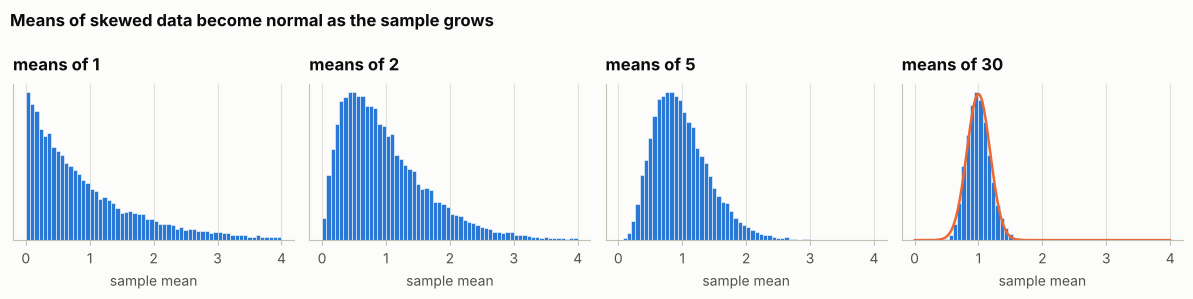

In [29]:
sizes = [1, 2, 5, 30]
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=False)
for ax, n_size in zip(axes, sizes):
    means = rng.exponential(scale=1.0, size=(20_000, n_size)).mean(axis=1)
    ax.hist(means, bins=np.linspace(0, 4, 61), density=True, color=PALETTE[0], edgecolor=SURFACE, linewidth=0.4)
    se = 1 / np.sqrt(n_size)
    xs = np.linspace(0, 4, 300)
    if n_size == 30:
        ax.plot(xs, normal_pdf(xs, 1, se), color=PALETTE[1], linewidth=1.8)
    ax.set_title(f"means of {n_size}")
    ax.set_xlabel("sample mean")
    ax.set_yticks([])
fig.suptitle("Means of skewed data become normal as the sample grows", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

With samples of 30, the means fit the normal curve (orange) closely, and they're bunched around the true mean of 1 with a spread of `σ / sqrt(n)`. That spread is called the **standard error**:

$$\text{SE} = \frac{\sigma}{\sqrt{n}}$$

It's the same `1 / sqrt(n)` as the die rolls in section 7, and it's why a model evaluated on 100 test examples has an uncertainty of several percentage points.

### The bootstrap

The standard error formula works for means. For other statistics (a median, an accuracy, a difference between two models) there's often no simple formula. The **bootstrap** gets the uncertainty by simulation instead:

1. Resample the data **with replacement**, the same size as the original.
2. Compute the statistic on the resample.
3. Repeat thousands of times. The spread of the results estimates the uncertainty.

A 95% **confidence interval** is the range between the 2.5th and 97.5th percentiles of the bootstrap results. Here it is for the median penguin body mass:

In [30]:
mass = penguins["body_mass_g"].dropna().to_numpy()

boot_medians = np.array([
    np.median(rng.choice(mass, size=len(mass), replace=True))
    for _ in range(5000)
])
low, high = np.percentile(boot_medians, [2.5, 97.5])
print(f"median body mass: {np.median(mass):.0f} g, 95% CI {low:.0f} to {high:.0f} g (n = {len(mass)})")

median body mass: 4050 g, 95% CI 3900 to 4200 g (n = 342)


Resampling with replacement mimics collecting a new dataset from the same population: some penguins appear twice, some not at all. It assumes the data you have is representative, which is the same assumption every model makes.

### Is a difference real? The permutation test

Two groups have different averages. Is that a real difference, or could it happen by chance? A **permutation test** answers by simulation:

1. If the group labels didn't matter, shuffling them shouldn't change much.
2. So shuffle the labels thousands of times and compute the difference each time.
3. The **p-value** is the fraction of shuffles that give a difference at least as large as the real one.

Two questions about Adelie penguins: do males have longer flippers than females, and are penguins on Dream island heavier than those on Torgersen?

In [31]:
def permutation_test(a, b, n_perm=10_000, rng=rng):
    observed = a.mean() - b.mean()
    pooled = np.concatenate([a, b])
    count = 0
    for _ in range(n_perm):
        shuffled = rng.permutation(pooled)
        diff = shuffled[:len(a)].mean() - shuffled[len(a):].mean()
        count += abs(diff) >= abs(observed)
    return observed, (count + 1) / (n_perm + 1)


adelie = penguins[penguins["species"] == "Adelie"]
male = adelie.loc[adelie["sex"] == "male", "flipper_length_mm"].dropna().to_numpy()
female = adelie.loc[adelie["sex"] == "female", "flipper_length_mm"].dropna().to_numpy()
dream = adelie.loc[adelie["island"] == "Dream", "body_mass_g"].dropna().to_numpy()
torgersen = adelie.loc[adelie["island"] == "Torgersen", "body_mass_g"].dropna().to_numpy()

diff, p = permutation_test(male, female)
print(f"flipper length, male minus female: {diff:+.1f} mm, p = {p:.4f}")
diff, p = permutation_test(dream, torgersen)
print(f"body mass, Dream minus Torgersen:  {diff:+.1f} g, p = {p:.2f}")

flipper length, male minus female: +4.6 mm, p = 0.0001


body mass, Dream minus Torgersen:  -18.0 g, p = 0.83


Two clear answers:

- Males' flippers are about 4.6 mm longer, and **no shuffle out of 10,000** produced a difference that big. The `+ 1` in the formula counts the real arrangement as one of the possibilities, so the p-value can't be exactly 0; it just says "less than 1 in 10,000".
- The island difference is under 20 g, for penguins that weigh around 3,700 g. Shuffled labels produce a difference at least that large most of the time (p above 0.8). There's no evidence of a difference.

A small p-value means "chance alone rarely produces this", not "this is important". With enough data, a 1 g difference would be "significant" too. Always report the size of the difference along with the p-value.

The same test is how you check whether one model is really better than another on the same test set, which you'll do in the mini project.

## 9. Information: entropy and cross-entropy

The most common loss function for classification, **cross-entropy**, comes from information theory. It's worth seeing where it comes from.

The **entropy** of a probability distribution measures its uncertainty:

$$H(p) = -\sum_i p_i \log p_i$$

A fair coin has the most uncertainty a coin can have; a coin that always lands heads has none:

In [32]:
def entropy(p):
    p = np.asarray(p, dtype=float)
    p = p[p > 0]                         # 0 log 0 counts as 0
    return np.sum(p * np.log2(1 / p))    # same as -sum(p log p)


for coin in [[0.5, 0.5], [0.9, 0.1], [0.99, 0.01], [1.0, 0.0]]:
    print(f"coin {coin}: {entropy(coin):.3f} bits")
print(f"fair die: {entropy(np.ones(6) / 6):.3f} bits")

coin [0.5, 0.5]: 1.000 bits
coin [0.9, 0.1]: 0.469 bits
coin [0.99, 0.01]: 0.081 bits
coin [1.0, 0.0]: 0.000 bits
fair die: 2.585 bits


With `log2`, entropy is measured in **bits**: a fair coin flip is 1 bit of information. ML code usually uses the natural log (units called nats), which only changes the scale.

**Cross-entropy** measures how well a predicted distribution `q` matches the true distribution `p`:

$$H(p, q) = -\sum_i p_i \log q_i$$

For classification, the true distribution is all on the correct class (a one-hot vector), so the sum has one term: **minus the log of the probability the model gave to the right answer**. That's the loss from Module 6.

Plotting it shows why it's a good loss:

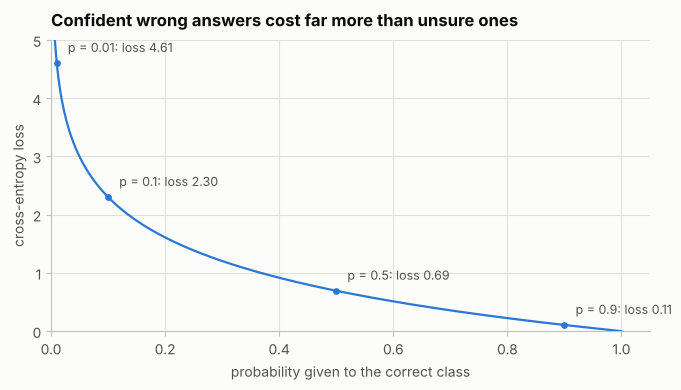

In [33]:
q = np.linspace(0.001, 1, 500)

fig, ax = plt.subplots()
ax.plot(q, -np.log(q), color=PALETTE[0])
for prob in [0.9, 0.5, 0.1, 0.01]:
    ax.scatter([prob], [-np.log(prob)], color=PALETTE[0], s=24, zorder=3)
    ax.annotate(f"p = {prob}: loss {-np.log(prob):.2f}", xy=(prob, -np.log(prob)), xytext=(8, 8),
                textcoords="offset points", color=INK_2, fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 5)
ax.set_xlabel("probability given to the correct class")
ax.set_ylabel("cross-entropy loss")
ax.set_title("Confident wrong answers cost far more than unsure ones")
fig.tight_layout()
plt.show()

A model that gives the right class 90% probability pays 0.11. One that's unsure (50%) pays 0.69. One that's confidently wrong, giving the right class 1%, pays 4.6, over 40 times as much. Accuracy treats all wrong answers the same; cross-entropy punishes overconfidence, which pushes models towards honest probabilities.

It also explains a practical detail: `log(0)` is minus infinity. If a model ever assigns probability 0 to the true class, the loss is infinite and training breaks. That's why code clips probabilities to a tiny minimum, like `1e-12`, or better, works with log-probabilities from the start (log-sum-exp, section 1).

**The KL divergence** is the gap between cross-entropy and entropy, `H(p, q) - H(p)`. It's zero only when `q` equals `p`, and you'll meet it in variational autoencoders and in knowledge distillation.

In [34]:
p_true = np.array([0.7, 0.2, 0.1])
q_model = np.array([0.5, 0.3, 0.2])

h_p = -np.sum(p_true * np.log(p_true))
h_pq = -np.sum(p_true * np.log(q_model))
print(f"entropy H(p):         {h_p:.4f} nats")
print(f"cross-entropy H(p,q): {h_pq:.4f} nats")
print(f"KL divergence:        {h_pq - h_p:.4f} nats")
print(f"KL of p with itself:  {-np.sum(p_true * np.log(p_true)) - h_p:.4f}")

entropy H(p):         0.8018 nats
cross-entropy H(p,q): 0.8869 nats
KL divergence:        0.0851 nats
KL of p with itself:  0.0000


## Summary

- **Floats are approximate.** Compare with `np.isclose`, never `==`. Avoid subtracting large, nearly equal numbers. Subtract the maximum before `exp` (stable softmax, log-sum-exp).
- **Vectors and matrices:** the dot product is the core operation. Cosine similarity compares directions, ignoring length. `X @ w` predicts for every row. Check shapes: `(n, d) @ (d, k) -> (n, k)`. Use `solve` and `lstsq`, not `inv`.
- **Derivatives:** the central difference is far more accurate than the forward one; `h = 1e-5` is a good default. Too small an `h` lets rounding error take over.
- **Gradients** point uphill, perpendicular to contours. A **gradient check** compares a hand-derived gradient with the numerical one.
- **The chain rule** multiplies local derivatives backwards through the computation. That's backpropagation. Gradients **accumulate** (`+=`) when a value is used more than once.
- **Gradient descent:** the steepest direction limits the learning rate; the shallowest sets how long it takes. Standardise features to make the bowl round. Test training code against exact answers when you can.
- **Probability:** simulate to check your reasoning. Mind the base rate (Bayes' rule).
- **Statistics:** use `ddof=1` for sample variance. Uncertainty shrinks like `1 / sqrt(n)`. The **bootstrap** gives confidence intervals for any statistic; a **permutation test** checks whether a difference could be chance. Report the size of an effect, not just the p-value.
- **Cross-entropy** is minus the log probability of the right answer. It punishes confident mistakes and needs clipping or log-space computation.

Next, open `02_exercises.ipynb`.